## **Visual validation**

**Install Libraries**

In [ ]:
pip install gseapy pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 597.5/597.5 kB 9.7 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import random
import gseapy as gp
import matplotlib.pyplot as plt
import random
import numpy as np
import matplotlib.pyplot as plt
from gseapy import enrichr

## **Load Data**

In [ ]:
# Load your dataset
df = pd.read_csv("labeled_lioness_data.csv")

# Extract unique genes from 'gene' and 'tf' columns
unique_genes = df['gene'].unique()
unique_tfs = df['tf'].unique()

# Merge both and remove duplicates to create a full background gene set
background_genes = list(set(unique_genes).union(set(unique_tfs)))

# Verify size
print(f"Total background genes: {len(background_genes)}")  # Should be 359

Total background genes: 359


In [ ]:
discovery_genes = [
    'MAGED1', 'TAF9B', 'AIFM1', 'MAOB', 'TMSB15A', 'MAP3K15', 'SLC6A8', 'NDUFB11', 'GAGE12G',
    'ZC3H12B', 'HS6ST2', 'GAGE12D', 'RBM10', 'BEX5', 'RPS4Y1', 'ARSD', 'PDZD4', 'KIAA1210',
    'RAI2', 'FRMPD4', 'CXorf38', 'NLGN4Y', 'FTHL17', 'KDM6A', 'ARHGEF9', 'UTY', 'NDUFA1',
    'IRAK1', 'IGBP1', 'ZMAT1', 'PIGA', 'RBMY1D', 'CSAG1', 'DMD', 'NLGN4X', 'SH3KBP1', 'TMSB4X',
    'PPEF1', 'MSL3', 'ZNF630', 'SASH3', 'GPM6B', 'TAF7L', 'ZFY', 'MID1IP1', 'SLC38A5', 'SLC25A14',
    'ARHGAP4', 'ARHGEF6', 'KIF4A', 'HSD17B10', 'TFE3', 'NLGN3', 'PAK3', 'BTK', 'TSPAN6', 'KLHL34',
    'APOOL', 'MAMLD1', 'CSTF2', 'GRIA3', 'PFKFB1', 'GABRQ', 'PCDH19', 'MBTPS2', 'MAGIX', 'CDK16',
    'ARHGAP6', 'DDX3X', 'UPRT', 'RAP2C', 'NUDT10', 'FAM9B', 'GAGE12B', 'ZRSR2', 'CNKSR2', 'PCDH11Y',
    'GAGE12H', 'ZNF449', 'AP1S2', 'ZNF81', 'AMOT', 'PAGE2B', 'SLC25A43', 'BCORL1', 'RAB41', 'SCML1',
    'SLC25A5', 'TSPY1', 'CLCN5', 'NHS', 'NAP1L3', 'PDZD11', 'ZXDA', 'ATRX', 'CITED1', 'UBQLN2',
    'ARMCX2', 'RPL10', 'TBL1X', 'RIBC1', 'CHIC1', 'MORF4L2', 'VBP1', 'MBNL3', 'MAGEC3', 'BCOR',
    'HMGB3', 'LONRF3', 'AFF2', 'FGF16', 'NDP', 'RPS4X', 'PIM2', 'DUSP9', 'OTUD5', 'BEND2',
    'HCFC1', 'FAM47C', 'IL1RAPL1', 'TMEM187', 'PJA1', 'FAM3A', 'DYNLT3', 'STARD8', 'SH3BGRL',
    'PRRG3', 'PGK1', 'UBL4A', 'ARMCX1', 'DDX3Y', 'NAA10', 'SHROOM2', 'RPGR', 'FGF13'
]

print(f"Number of discovery genes: {len(discovery_genes)}")  # Should be 135

Number of discovery genes: 135


In [ ]:
# Ottieni i "non-discovery", cioè il tuo background
complementary_genes = list(set(background_genes) - set(discovery_genes))

print(f"Number of complementary genes: {len(complementary_genes)}")  # Should be 224

Number of complementary genes: 224


### **1) Hypergeometric Test**

This function performs a hypergeometric test to evaluate whether a given gene set is significantly enriched for genes from a specific biological pathway. It computes the probability of observing at least the observed overlap between the gene set and the pathway genes, given the size of the background population. The p-value reflects how likely it is to obtain such an overlap by chance.


In [ ]:
from scipy.stats import hypergeom

def hypergeom_pval(gene_set, background_genes, pathway_genes):
    # Total number of genes in the background population
    M = len(background_genes)

    # Number of genes in the test set (subset of interest)
    N = len(gene_set)

    # Genes in the pathway that are also in the background
    pathway_in_bg = set(pathway_genes) & set(background_genes)

    # Number of pathway genes present in the background
    K = len(pathway_in_bg)

    # Number of overlapping genes between the gene set and the pathway (observed overlap)
    X = len(set(gene_set) & pathway_in_bg)

    # If there are no pathway genes in the background, return None (no test possible)
    if K == 0:
        return None

    # Calculate the hypergeometric p-value for enrichment:
    # Probability of observing X or more overlapping genes by chance
    return hypergeom.sf(X - 1, M, K, N)

### **2) Compute the metric**

For each pathway:
* Check if there is any overlap between the pathway genes and your gene subset.
* Apply the hypergeometric test to estimate the significance of this overlap.
* If the p-value is below the threshold (e.g., 0.05), consider the pathway “significant.”
* Add the genes from the subset that are present in these significant pathways → gene overlap.

In [ ]:
def metric_num_genes_overlap(gene_subset, background_genes, pathway_db, pval_threshold=0.05):
    """
    Calculates the number of genes from the given subset that overlap with significantly enriched pathways.

    Parameters:
    - gene_subset: list or set of genes to analyze.
    - background_genes: list or set representing the full background gene universe.
    - pathway_db: dictionary mapping pathway names to lists of genes in each pathway.
    - pval_threshold: significance threshold for the hypergeometric test (default 0.05).

    Procedure:
    - Initialize an empty set to store overlapping genes.
    - For each pathway in the pathway database:
      * Identify genes in the pathway that are also in the background.
      * If no genes overlap with the background, skip this pathway.
      * Compute the hypergeometric p-value for the overlap between the gene subset and pathway genes.
      * If the p-value is below the threshold, consider the pathway significantly enriched.
      * Add the genes from the subset that fall within this significant pathway to the overlapping set.
    - Return the total count of unique overlapping genes found in significant pathways.

    This metric provides a proxy for functional enrichment by counting how many genes from the subset participate
    in biologically relevant pathways.
    """
    overlapping_genes = set()
    for pathway, genes in pathway_db.items():
        pathway_in_bg = set(genes) & set(background_genes)
        if len(pathway_in_bg) == 0:
            continue
        pval = hypergeom_pval(gene_subset, background_genes, genes)
        if pval is not None and pval < pval_threshold:
            overlapping_genes.update(set(gene_subset) & pathway_in_bg)
    return len(overlapping_genes)


### **3) Plot**

* Progressively analyze subsets of increasing size (from 10% to 100%) from both my discovery gene set and the complementary gene set.
* For each subset size, I randomly sample subsets multiple times and calculate how many genes from each subset fall into significantly enriched pathways.
* By averaging these values and plotting them, I get a clear comparative picture of functional enrichment trends between my candidate genes and control genes.
* This helps to validate whether my discovery genes are functionally coherent and biologically meaningful, as expected for a true positive set.

In [ ]:
def cumulative_metric_overlap_plot(discovery_genes, complementari, pathway_db, background_genes, steps=10, n_repeats=50):
    """
    Generates a cumulative enrichment plot comparing discovery genes against complementary genes.

    Parameters:
    - discovery_genes: list of genes of interest (e.g., identified candidate genes).
    - complementari: list of complementary or control genes (e.g., remaining genes).
    - pathway_db: dictionary of pathways and their associated genes.
    - background_genes: list or set of all background genes considered for enrichment.
    - steps: number of increments (fractions) to test from 10% to 100% of gene subsets.
    - n_repeats: number of random samplings per fraction for averaging.

    What it does:
    - Defines fractions from 10% to 100% of the discovery and complementary gene sets.
    - For each fraction, repeatedly samples random subsets of genes from both groups.
    - For each subset, computes the metric of interest: the number of genes overlapping significantly enriched pathways
      (using the 'metric_num_genes_overlap' function).
    - Averages the metric values over multiple repeats to obtain robust estimates.
    - Collects these average values for all fractions for both gene groups.
    - Plots the cumulative metric (y-axis) against the percentage of genes considered (x-axis) for both groups on the same plot.

    Purpose and interpretation:
    - The plot visualizes how functional enrichment (number of genes in significant pathways) changes as you increase
      the fraction of genes considered.
    - A steadily increasing curve for discovery genes suggests strong biological relevance and pathway coherence.
    - A flat or decreasing curve for complementary genes suggests weaker or random enrichment.
    - This comparative approach helps validate the biological significance of the discovery gene set relative to controls.

    Plot details:
    - X-axis: Percentage of genes included (from 10% to 100%).
    - Y-axis: Average number of genes that fall into significantly enriched pathways.
    - Two lines: one for discovery genes (in blue) and one for complementary genes (in orange).

    The function sets a random seed (42) to ensure reproducible sampling results.
    """
    random.seed(42)

    discovery_sizes = np.linspace(0.1, 1.0, steps)
    complementari_sizes = np.linspace(0.1, 1.0, steps)

    discovery_metrics = []
    complementari_metrics = []

    N_discovery = len(discovery_genes)
    N_complementari = len(complementari)

    # Compute metrics for increasing fractions of discovery genes
    for frac in discovery_sizes:
        n_genes = max(1, int(N_discovery * frac))
        vals = []
        for _ in range(n_repeats):
            subset = random.sample(discovery_genes, n_genes)
            metric_val = metric_num_genes_overlap(subset, background_genes, pathway_db)
            vals.append(metric_val)
        discovery_metrics.append(np.mean(vals))

    # Compute metrics for increasing fractions of complementary genes
    for frac in complementari_sizes:
        n_genes = max(1, int(N_complementari * frac))
        vals = []
        for _ in range(n_repeats):
            subset = random.sample(complementari, n_genes)
            metric_val = metric_num_genes_overlap(subset, background_genes, pathway_db)
            vals.append(metric_val)
        complementari_metrics.append(np.mean(vals))

    # Plotting the results
    plt.figure(figsize=(10, 6))
    plt.plot(discovery_sizes * 100, discovery_metrics, label="Discovery genes",
             marker='o', color='#1f77b4', linewidth=2.5)
    plt.plot(complementari_sizes * 100, complementari_metrics, label="Complementary genes",
             marker='x', color='#ff7f0e', linewidth=2.5)

    plt.xlabel("Percentage of genes considered (%)", fontsize=12)
    plt.ylabel("Number of genes in enriched pathways", fontsize=12)
    plt.title("Functional Enrichment: Discovery vs Complementary Genes", fontsize=14, weight='bold')

    plt.legend(fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    plt.tight_layout()
    plt.show()


**Plot with max and min bands**

In [ ]:
def cumulative_metric_overlap_plot_filled(
    discovery_genes, complementari, pathway_db, background_genes,
    steps=10, n_repeats=50
):
    import numpy as np
    import matplotlib.pyplot as plt
    import random
    from matplotlib.ticker import MaxNLocator

    random.seed(42)

    discovery_sizes = np.linspace(0.1, 1.0, steps)
    complementari_sizes = np.linspace(0.1, 1.0, steps)

    discovery_means, discovery_stds = [], []
    complementari_means, complementari_stds = [], []

    N_discovery = len(discovery_genes)
    N_complementari = len(complementari)

    # --- Discovery ---
    for frac in discovery_sizes:
        n_genes = max(1, int(N_discovery * frac))
        vals = [
            metric_num_genes_overlap(random.sample(discovery_genes, n_genes),
                                     background_genes, pathway_db)
            for _ in range(n_repeats)
        ]
        discovery_means.append(np.mean(vals))
        discovery_stds.append(np.std(vals))

    # --- Complementary ---
    for frac in complementari_sizes:
        n_genes = max(1, int(N_complementari * frac))
        vals = [
            metric_num_genes_overlap(random.sample(complementari, n_genes),
                                     background_genes, pathway_db)
            for _ in range(n_repeats)
        ]
        complementari_means.append(np.mean(vals))
        complementari_stds.append(np.std(vals))

    discovery_means = np.array(discovery_means)
    discovery_stds = np.array(discovery_stds)
    complementari_means = np.array(complementari_means)
    complementari_stds = np.array(complementari_stds)

    # --- Plot ---
    plt.figure(figsize=(10, 6))

    # verde (discovery)
    plt.plot(discovery_sizes * 100, discovery_means,
             label="Discovery genes", marker='o',
             color='#2ca02c', linewidth=2.5)
    plt.fill_between(discovery_sizes * 100,
                     discovery_means - discovery_stds,
                     discovery_means + discovery_stds,
                     color='#2ca02c', alpha=0.25)

    # fucsia (complementary)
    plt.plot(complementari_sizes * 100, complementari_means,
             label="Complementary genes", marker='x',
             color='#e377c2', linewidth=2.5)
    plt.fill_between(complementari_sizes * 100,
                     complementari_means - complementari_stds,
                     complementari_means + complementari_stds,
                     color='#e377c2', alpha=0.25)

    plt.xlabel("Percentage of genes considered (%)", fontsize=12)
    plt.ylabel("Number of genes in enriched pathways", fontsize=12)
    plt.title("Functional Enrichment: Discovery vs Complementary Genes",
              fontsize=14, weight='bold')

    plt.legend(fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.6)

    # forza tick Y ad interi
    plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))

    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    plt.tight_layout()
    plt.show()


1) Pathway *Reactome*

In [ ]:
def read_gmt(file_path):
    """
    Reads a .gmt file and returns a dictionary:
    { pathway_name: [gene1, gene2, ...], ... }
    """
    pathway_db = {}
    with open(file_path, 'r') as f:
        for line in f:
            # Split the line by tabs
            parts = line.strip().split('\t')
            # The first part is the pathway name
            pathway_name = parts[0]
            # The second part is usually a description or URL, ignored here
            # The remaining parts are the genes in the pathway
            genes = parts[2:]
            # Store pathway and associated genes in the dictionary
            pathway_db[pathway_name] = genes
    return pathway_db


# Path to the downloaded .gmt file
file_gmt = "c2.cp.reactome.v2025.1.Hs.symbols.gmt.txt"

# Load the pathways and genes into a dictionary
pathway_db = read_gmt(file_gmt)

### **2) Compute the metric**

For each pathway:
* Check if there is any overlap between the pathway genes and your gene subset.
* Apply the hypergeometric test to estimate the significance of this overlap.
* If the p-value is below the threshold (e.g., 0.05), consider the pathway “significant.”
* Add the genes from the subset that are present in these significant pathways → gene overlap.

In [ ]:
def metric_num_genes_overlap(gene_subset, background_genes, pathway_db, pval_threshold=0.05):
    """
    Calculates the number of genes from the given subset that overlap with significantly enriched pathways.

    Parameters:
    - gene_subset: list or set of genes to analyze.
    - background_genes: list or set representing the full background gene universe.
    - pathway_db: dictionary mapping pathway names to lists of genes in each pathway.
    - pval_threshold: significance threshold for the hypergeometric test (default 0.05).

    Procedure:
    - Initialize an empty set to store overlapping genes.
    - For each pathway in the pathway database:
      * Identify genes in the pathway that are also in the background.
      * If no genes overlap with the background, skip this pathway.
      * Compute the hypergeometric p-value for the overlap between the gene subset and pathway genes.
      * If the p-value is below the threshold, consider the pathway significantly enriched.
      * Add the genes from the subset that fall within this significant pathway to the overlapping set.
    - Return the total count of unique overlapping genes found in significant pathways.

    This metric provides a proxy for functional enrichment by counting how many genes from the subset participate
    in biologically relevant pathways.
    """
    overlapping_genes = set()
    for pathway, genes in pathway_db.items():
        pathway_in_bg = set(genes) & set(background_genes)
        if len(pathway_in_bg) == 0:
            continue
        pval = hypergeom_pval(gene_subset, background_genes, genes)
        if pval is not None and pval < pval_threshold:
            overlapping_genes.update(set(gene_subset) & pathway_in_bg)
    return len(overlapping_genes)


### **3) Plot**

* Progressively analyze subsets of increasing size (from 10% to 100%) from both my discovery gene set and the complementary gene set.
* For each subset size, I randomly sample subsets multiple times and calculate how many genes from each subset fall into significantly enriched pathways.
* By averaging these values and plotting them, I get a clear comparative picture of functional enrichment trends between my candidate genes and control genes.
* This helps to validate whether my discovery genes are functionally coherent and biologically meaningful, as expected for a true positive set.

**135 vs 224**

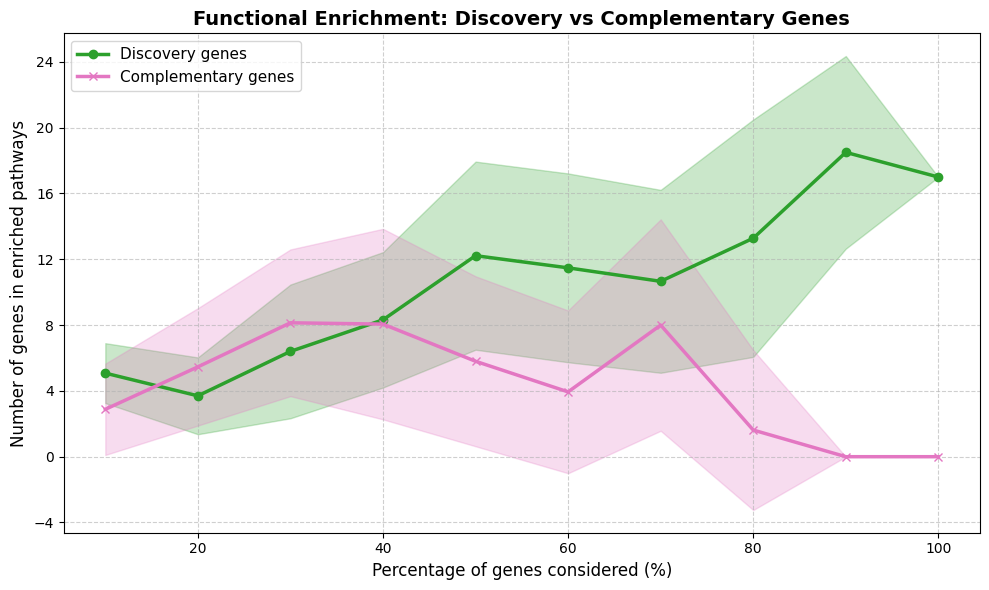

In [ ]:
background_genes = list(set(discovery_genes + complementary_genes))

cumulative_metric_overlap_plot_filled(discovery_genes, complementary_genes, pathway_db, background_genes, steps=10)

**135 vs 135**

In [ ]:
random.seed(10)
matched_control = random.sample(complementary_genes, len(discovery_genes))

In [ ]:
background_genes = list(set(discovery_genes + complementary_genes)) #da capire se tenere 359 o 270(135+135)

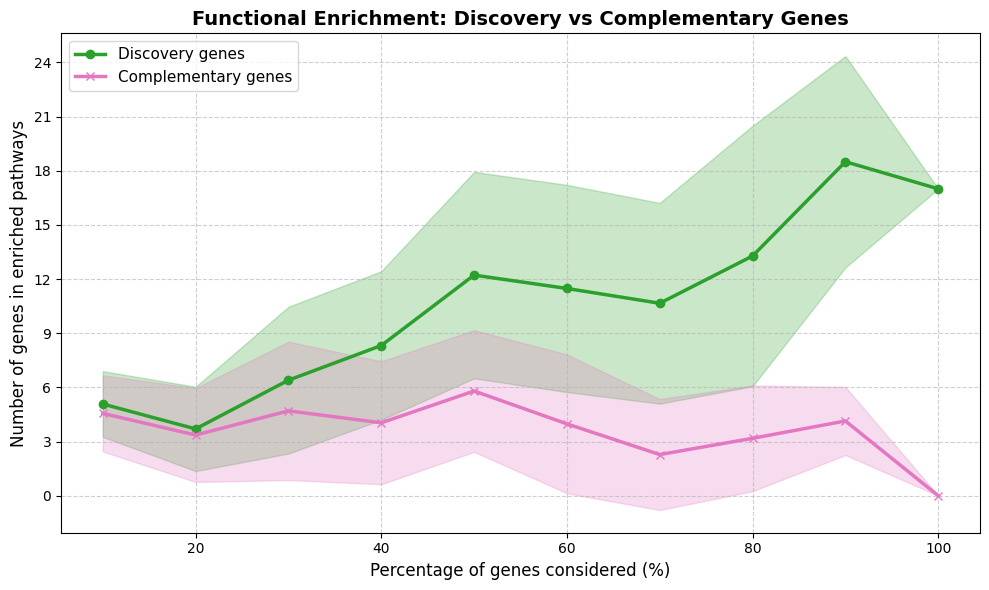

In [ ]:
cumulative_metric_overlap_plot_filled(discovery_genes, matched_control, pathway_db, background_genes, steps=10)


In [ ]:
def cumulative_metric_overlap_ratio(discovery_genes, complementari,
                                    pathway_db, background_genes,
                                    steps=10, n_repeats=50):
    import numpy as np, random, matplotlib.pyplot as plt
    random.seed(42)

    fractions = np.linspace(0.1, 1.0, steps)
    ratios = []

    N_discovery = len(discovery_genes)
    N_complementari = len(complementari)

    for frac in fractions:
        n_disc = max(1, int(N_discovery * frac))
        n_comp = max(1, int(N_complementari * frac))

        vals_disc = [metric_num_genes_overlap(random.sample(discovery_genes, n_disc),
                                              background_genes, pathway_db)
                     for _ in range(n_repeats)]
        vals_comp = [metric_num_genes_overlap(random.sample(complementari, n_comp),
                                              background_genes, pathway_db)
                     for _ in range(n_repeats)]

        mean_disc = np.mean(vals_disc)
        mean_comp = np.mean(vals_comp)

        # evita divisioni per zero
        ratio = mean_disc / mean_comp if mean_comp > 0 else np.nan
        ratios.append(ratio)

    # Plot
    plt.figure(figsize=(9, 6))
    plt.plot(fractions * 100, ratios, marker='o', color='#8B0000',
             linewidth=2.5, label="Discovery / Complementary")
    plt.axhline(1, color='gray', linestyle='--', linewidth=1.5)  # baseline = pari prestazioni
    plt.xlabel("Percentage of genes considered (%)", fontsize=12)
    plt.ylabel("Performance ratio (Discovery / Complementary)", fontsize=12)
    plt.title("Relative Functional Enrichment", fontsize=14, weight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()


**135 vs 224**

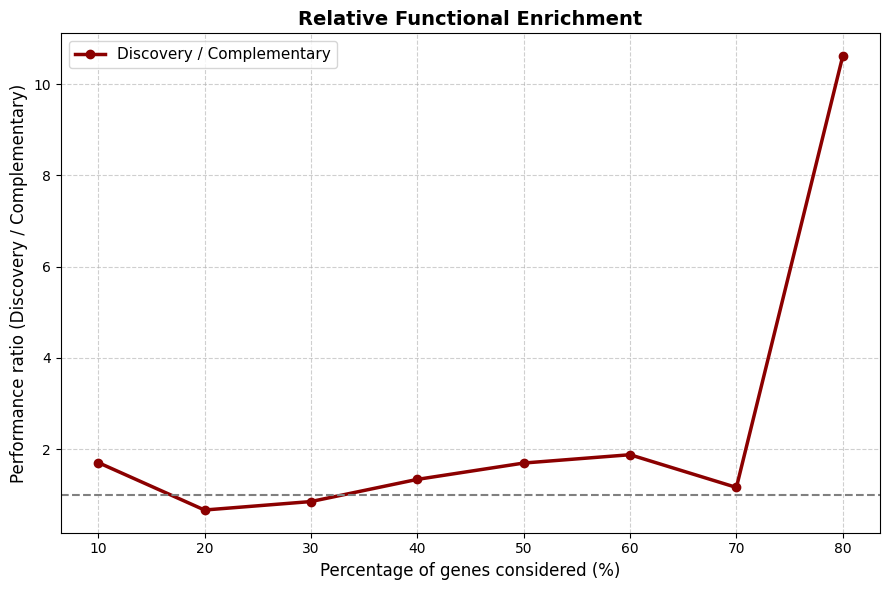

In [ ]:
background_genes = list(set(discovery_genes + complementary_genes))

cumulative_metric_overlap_ratio(discovery_genes, complementary_genes, pathway_db, background_genes, steps=10)

**135 vs 135**

In [ ]:
random.seed(12)
matched_control = random.sample(complementary_genes, len(discovery_genes))

In [ ]:
background_genes = list(set(discovery_genes + complementary_genes)) #da capire se tenere 359 o 270(135+135)

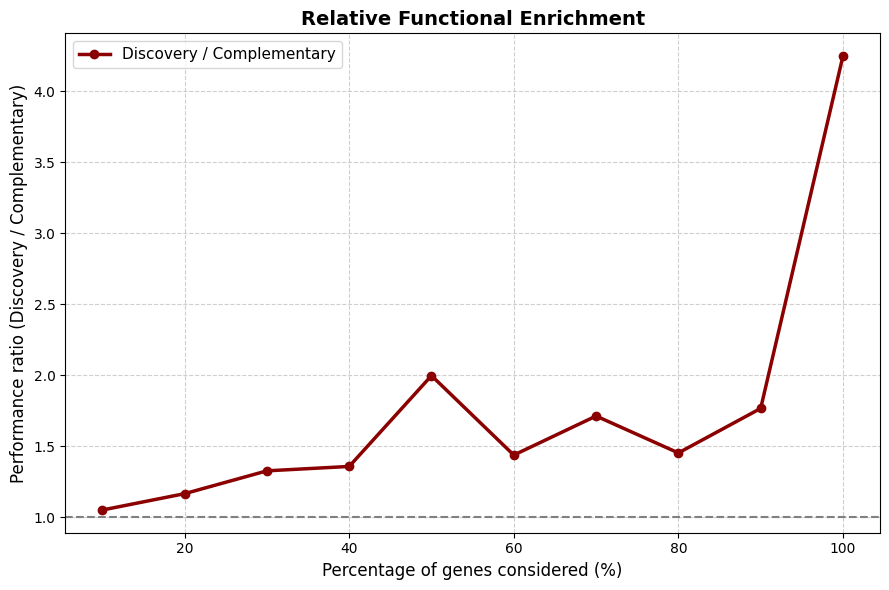

In [ ]:
cumulative_metric_overlap_ratio(discovery_genes, matched_control, pathway_db, background_genes, steps=10)


3) Pathway *WikiPathways Curated Collection*

In [ ]:
def read_gmt(file_path):
    """
    Reads a .gmt file and returns a dictionary:
    { pathway_name: [gene1, gene2, ...], ... }
    """
    pathway_db = {}
    with open(file_path, 'r') as f:
        for line in f:
            # Split the line by tabs
            parts = line.strip().split('\t')
            # The first part is the pathway name
            pathway_name = parts[0]
            # The second part is usually a description or URL, ignored here
            # The remaining parts are the genes in the pathway
            genes = parts[2:]
            # Store pathway and associated genes in the dictionary
            pathway_db[pathway_name] = genes
    return pathway_db


# Path to the downloaded .gmt file
file_gmt = "c2.cp.wikipathways.v2025.1.Hs.symbols.gmt.txt"

# Load the pathways and genes into a dictionary
pathway_db = read_gmt(file_gmt)

### **2) Compute the metric**

For each pathway:
* Check if there is any overlap between the pathway genes and your gene subset.
* Apply the hypergeometric test to estimate the significance of this overlap.
* If the p-value is below the threshold (e.g., 0.05), consider the pathway “significant.”
* Add the genes from the subset that are present in these significant pathways → gene overlap.

In [ ]:
def metric_num_genes_overlap(gene_subset, background_genes, pathway_db, pval_threshold=0.05):
    """
    Calculates the number of genes from the given subset that overlap with significantly enriched pathways.

    Parameters:
    - gene_subset: list or set of genes to analyze.
    - background_genes: list or set representing the full background gene universe.
    - pathway_db: dictionary mapping pathway names to lists of genes in each pathway.
    - pval_threshold: significance threshold for the hypergeometric test (default 0.05).

    Procedure:
    - Initialize an empty set to store overlapping genes.
    - For each pathway in the pathway database:
      * Identify genes in the pathway that are also in the background.
      * If no genes overlap with the background, skip this pathway.
      * Compute the hypergeometric p-value for the overlap between the gene subset and pathway genes.
      * If the p-value is below the threshold, consider the pathway significantly enriched.
      * Add the genes from the subset that fall within this significant pathway to the overlapping set.
    - Return the total count of unique overlapping genes found in significant pathways.

    This metric provides a proxy for functional enrichment by counting how many genes from the subset participate
    in biologically relevant pathways.
    """
    overlapping_genes = set()
    for pathway, genes in pathway_db.items():
        pathway_in_bg = set(genes) & set(background_genes)
        if len(pathway_in_bg) == 0:
            continue
        pval = hypergeom_pval(gene_subset, background_genes, genes)
        if pval is not None and pval < pval_threshold:
            overlapping_genes.update(set(gene_subset) & pathway_in_bg)
    return len(overlapping_genes)


### **3) Plot**

* Progressively analyze subsets of increasing size (from 10% to 100%) from both my discovery gene set and the complementary gene set.
* For each subset size, I randomly sample subsets multiple times and calculate how many genes from each subset fall into significantly enriched pathways.
* By averaging these values and plotting them, I get a clear comparative picture of functional enrichment trends between my candidate genes and control genes.
* This helps to validate whether my discovery genes are functionally coherent and biologically meaningful, as expected for a true positive set.

**135 vs 224**

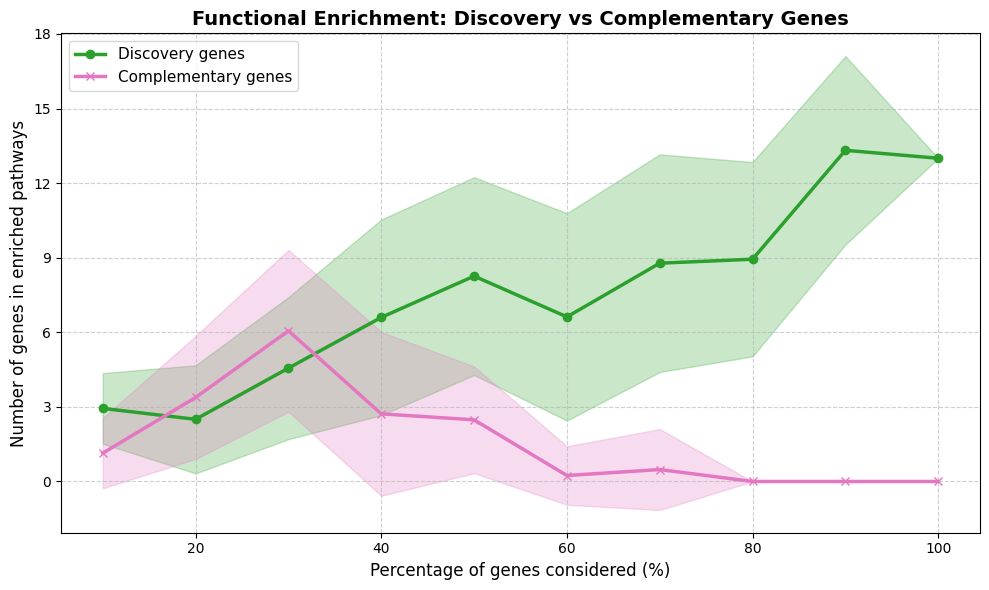

In [ ]:
background_genes = list(set(discovery_genes + complementary_genes))

cumulative_metric_overlap_plot_filled(discovery_genes, complementary_genes, pathway_db, background_genes, steps=10)

**135 vs 135**

In [ ]:
random.seed(10)
matched_control = random.sample(complementary_genes, len(discovery_genes))

In [ ]:
background_genes = list(set(discovery_genes + complementary_genes)) #da capire se tenere 359 o 270(135+135)

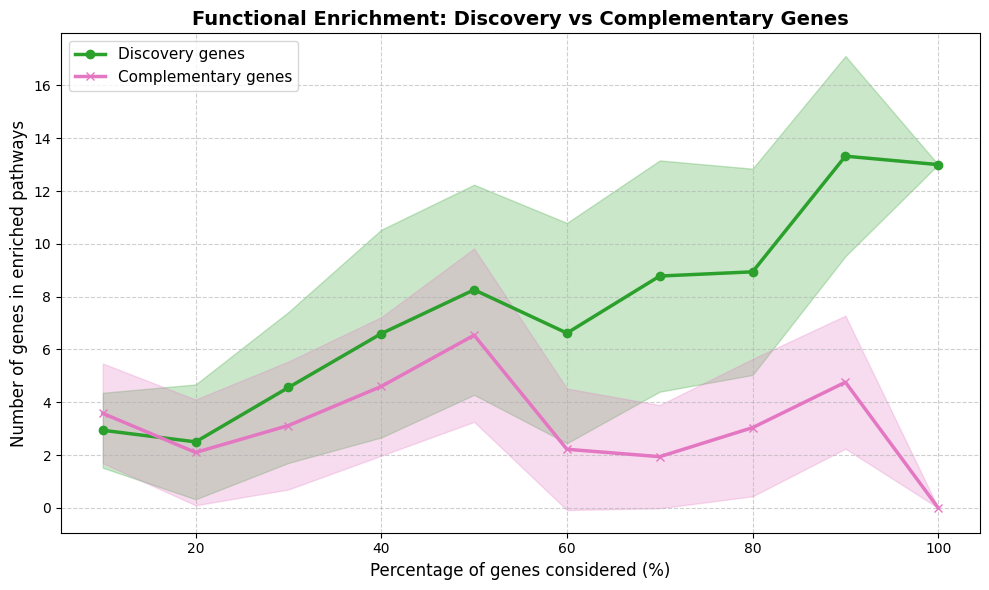

In [ ]:
cumulative_metric_overlap_plot_filled(discovery_genes, matched_control, pathway_db, background_genes, steps=10)


In [ ]:
def cumulative_metric_overlap_ratio(discovery_genes, complementari,
                                    pathway_db, background_genes,
                                    steps=10, n_repeats=50):
    import numpy as np, random, matplotlib.pyplot as plt
    random.seed(42)

    fractions = np.linspace(0.1, 1.0, steps)
    ratios = []

    N_discovery = len(discovery_genes)
    N_complementari = len(complementari)

    for frac in fractions:
        n_disc = max(1, int(N_discovery * frac))
        n_comp = max(1, int(N_complementari * frac))

        vals_disc = [metric_num_genes_overlap(random.sample(discovery_genes, n_disc),
                                              background_genes, pathway_db)
                     for _ in range(n_repeats)]
        vals_comp = [metric_num_genes_overlap(random.sample(complementari, n_comp),
                                              background_genes, pathway_db)
                     for _ in range(n_repeats)]

        mean_disc = np.mean(vals_disc)
        mean_comp = np.mean(vals_comp)

        # evita divisioni per zero
        ratio = mean_disc / mean_comp if mean_comp > 0 else np.nan
        ratios.append(ratio)

    # Plot
    plt.figure(figsize=(9, 6))
    plt.plot(fractions * 100, ratios, marker='o', color='#8B0000',
             linewidth=2.5, label="Discovery / Complementary")
    plt.axhline(1, color='gray', linestyle='--', linewidth=1.5)  # baseline = pari prestazioni
    plt.xlabel("Percentage of genes considered (%)", fontsize=12)
    plt.ylabel("Performance ratio (Discovery / Complementary)", fontsize=12)
    plt.title("Relative Functional Enrichment", fontsize=14, weight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()


**135 vs 224**

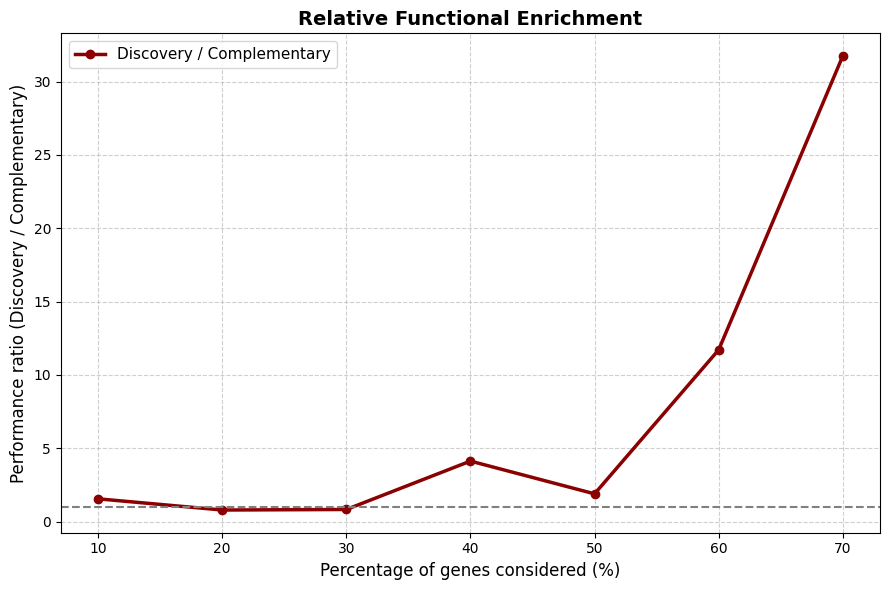

In [ ]:
background_genes = list(set(discovery_genes + complementary_genes))

cumulative_metric_overlap_ratio(discovery_genes, complementary_genes, pathway_db, background_genes, steps=10)

**135 vs 135**

In [ ]:
random.seed(10)
matched_control = random.sample(complementary_genes, len(discovery_genes))

In [ ]:
background_genes = list(set(discovery_genes + complementary_genes)) #da capire se tenere 359 o 270(135+135)

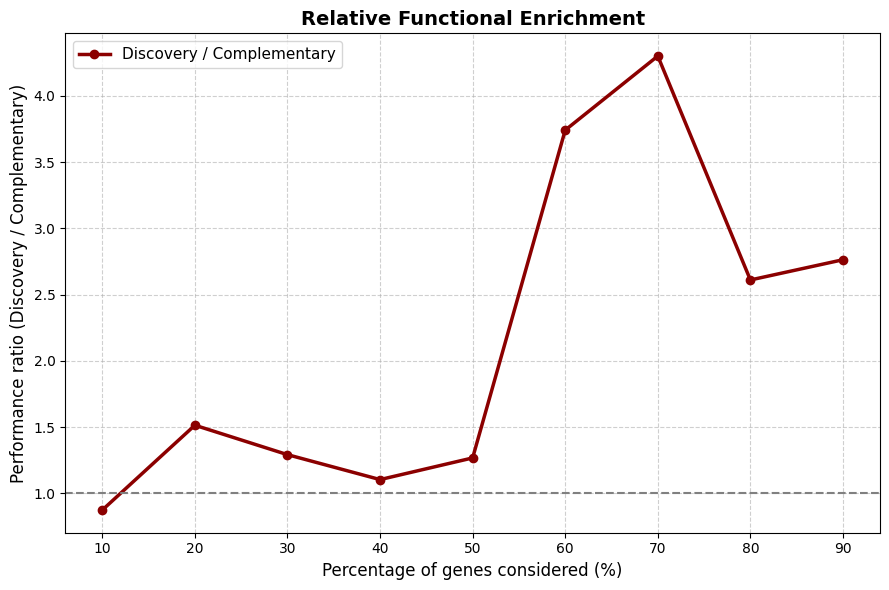

In [ ]:
cumulative_metric_overlap_ratio(discovery_genes, matched_control, pathway_db, background_genes, steps=10)


4) Pathway *canonical pathways*

In [ ]:
def read_gmt(file_path):
    """
    Reads a .gmt file and returns a dictionary:
    { pathway_name: [gene1, gene2, ...], ... }
    """
    pathway_db = {}
    with open(file_path, 'r') as f:
        for line in f:
            # Split the line by tabs
            parts = line.strip().split('\t')
            # The first part is the pathway name
            pathway_name = parts[0]
            # The second part is usually a description or URL, ignored here
            # The remaining parts are the genes in the pathway
            genes = parts[2:]
            # Store pathway and associated genes in the dictionary
            pathway_db[pathway_name] = genes
    return pathway_db


# Path to the downloaded .gmt file
file_gmt = "c2.cp.v2025.1.Hs.symbols.gmt.txt"

# Load the pathways and genes into a dictionary
pathway_db = read_gmt(file_gmt)

### **2) Compute the metric**

For each pathway:
* Check if there is any overlap between the pathway genes and your gene subset.
* Apply the hypergeometric test to estimate the significance of this overlap.
* If the p-value is below the threshold (e.g., 0.05), consider the pathway “significant.”
* Add the genes from the subset that are present in these significant pathways → gene overlap.

In [ ]:
def metric_num_genes_overlap(gene_subset, background_genes, pathway_db, pval_threshold=0.05):
    """
    Calculates the number of genes from the given subset that overlap with significantly enriched pathways.

    Parameters:
    - gene_subset: list or set of genes to analyze.
    - background_genes: list or set representing the full background gene universe.
    - pathway_db: dictionary mapping pathway names to lists of genes in each pathway.
    - pval_threshold: significance threshold for the hypergeometric test (default 0.05).

    Procedure:
    - Initialize an empty set to store overlapping genes.
    - For each pathway in the pathway database:
      * Identify genes in the pathway that are also in the background.
      * If no genes overlap with the background, skip this pathway.
      * Compute the hypergeometric p-value for the overlap between the gene subset and pathway genes.
      * If the p-value is below the threshold, consider the pathway significantly enriched.
      * Add the genes from the subset that fall within this significant pathway to the overlapping set.
    - Return the total count of unique overlapping genes found in significant pathways.

    This metric provides a proxy for functional enrichment by counting how many genes from the subset participate
    in biologically relevant pathways.
    """
    overlapping_genes = set()
    for pathway, genes in pathway_db.items():
        pathway_in_bg = set(genes) & set(background_genes)
        if len(pathway_in_bg) == 0:
            continue
        pval = hypergeom_pval(gene_subset, background_genes, genes)
        if pval is not None and pval < pval_threshold:
            overlapping_genes.update(set(gene_subset) & pathway_in_bg)
    return len(overlapping_genes)


### **3) Plot**

* Progressively analyze subsets of increasing size (from 10% to 100%) from both my discovery gene set and the complementary gene set.
* For each subset size, I randomly sample subsets multiple times and calculate how many genes from each subset fall into significantly enriched pathways.
* By averaging these values and plotting them, I get a clear comparative picture of functional enrichment trends between my candidate genes and control genes.
* This helps to validate whether my discovery genes are functionally coherent and biologically meaningful, as expected for a true positive set.

**135 vs 224**

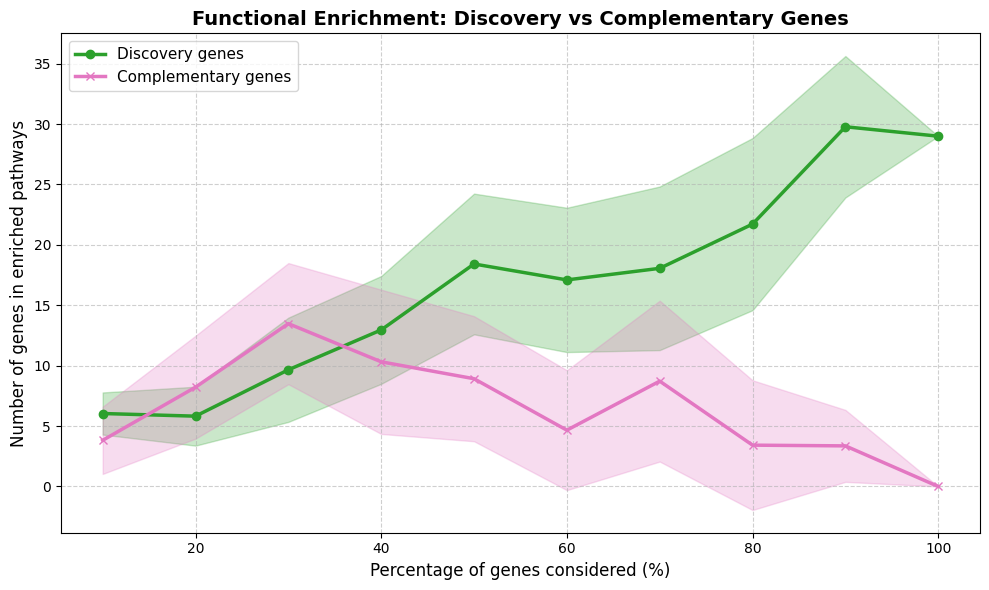

In [ ]:
background_genes = list(set(discovery_genes + complementary_genes))

cumulative_metric_overlap_plot_filled(discovery_genes, complementary_genes, pathway_db, background_genes, steps=10)

**135 vs 135**

In [ ]:
random.seed(12)
matched_control = random.sample(complementary_genes, len(discovery_genes))

In [ ]:
background_genes = list(set(discovery_genes + complementary_genes)) #da capire se tenere 359 o 270(135+135)

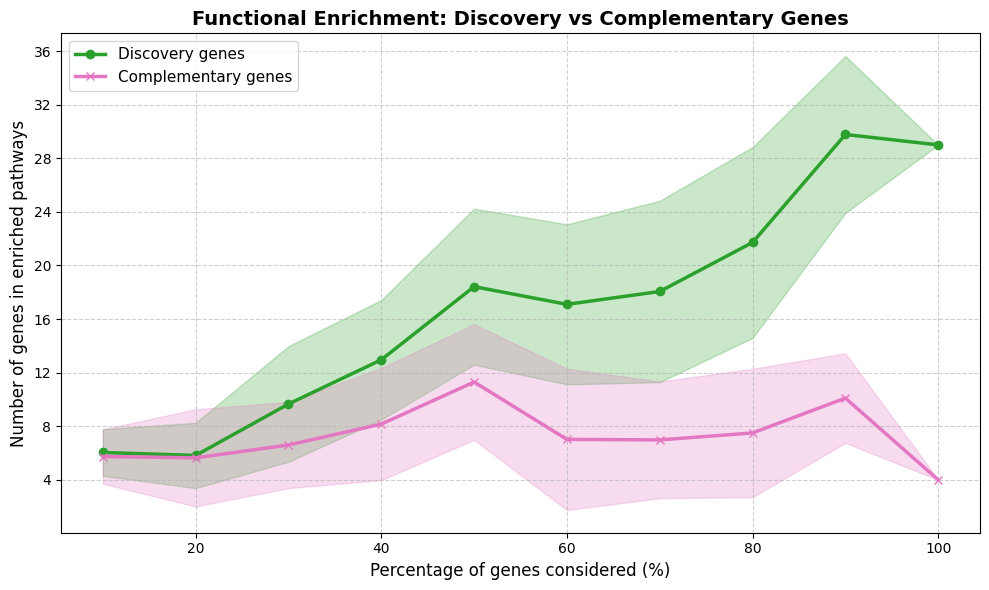

In [ ]:
cumulative_metric_overlap_plot_filled(discovery_genes, matched_control, pathway_db, background_genes, steps=10)


## **rapporto Discovery / Complementary**

In [ ]:
def cumulative_metric_overlap_ratio(discovery_genes, complementari,
                                    pathway_db, background_genes,
                                    steps=10, n_repeats=50):
    import numpy as np, random, matplotlib.pyplot as plt
    random.seed(42)

    fractions = np.linspace(0.1, 1.0, steps)
    ratios = []

    N_discovery = len(discovery_genes)
    N_complementari = len(complementari)

    for frac in fractions:
        n_disc = max(1, int(N_discovery * frac))
        n_comp = max(1, int(N_complementari * frac))

        vals_disc = [metric_num_genes_overlap(random.sample(discovery_genes, n_disc),
                                              background_genes, pathway_db)
                     for _ in range(n_repeats)]
        vals_comp = [metric_num_genes_overlap(random.sample(complementari, n_comp),
                                              background_genes, pathway_db)
                     for _ in range(n_repeats)]

        mean_disc = np.mean(vals_disc)
        mean_comp = np.mean(vals_comp)

        # evita divisioni per zero
        ratio = mean_disc / mean_comp if mean_comp > 0 else np.nan
        ratios.append(ratio)

    # Plot
    plt.figure(figsize=(9, 6))
    plt.plot(fractions * 100, ratios, marker='o', color='#8B0000',
             linewidth=2.5, label="Discovery / Complementary")
    plt.axhline(1, color='gray', linestyle='--', linewidth=1.5)  # baseline = pari prestazioni
    plt.xlabel("Percentage of genes considered (%)", fontsize=12)
    plt.ylabel("Performance ratio (Discovery / Complementary)", fontsize=12)
    plt.title("Relative Functional Enrichment", fontsize=14, weight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()


**135 vs 224**

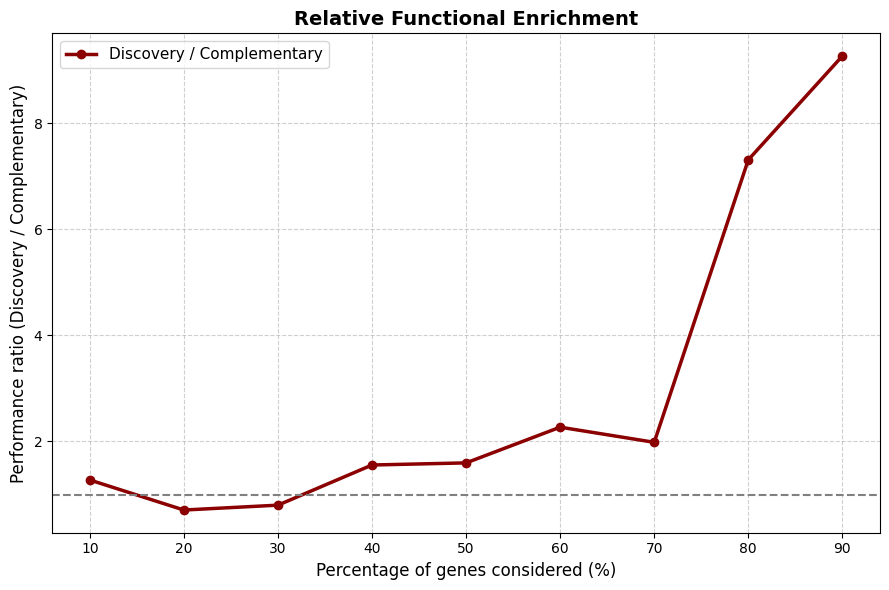

In [ ]:
background_genes = list(set(discovery_genes + complementary_genes))

cumulative_metric_overlap_ratio(discovery_genes, complementary_genes, pathway_db, background_genes, steps=10)

**135 vs 135**

In [ ]:
random.seed(12)
matched_control = random.sample(complementary_genes, len(discovery_genes))

In [ ]:
background_genes = list(set(discovery_genes + complementary_genes)) #da capire se tenere 359 o 270(135+135)

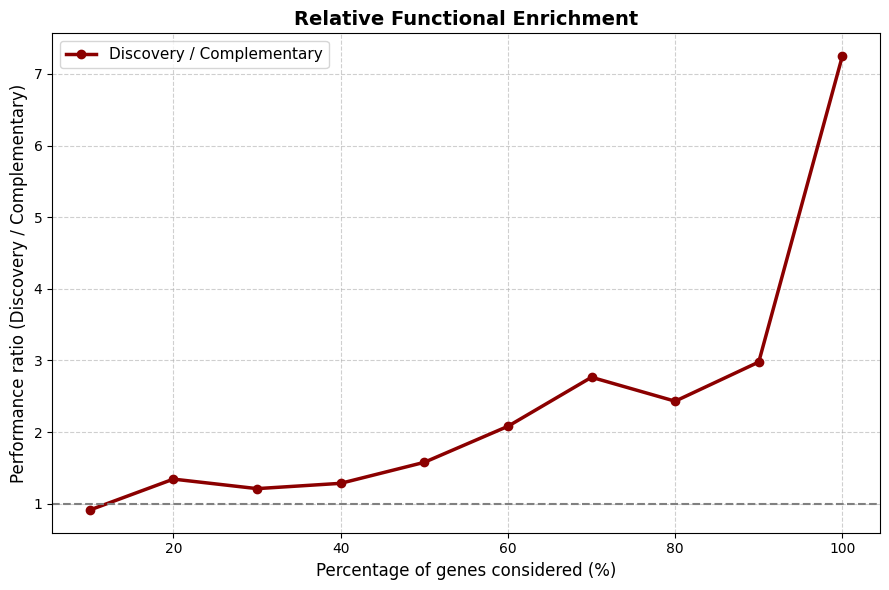

In [ ]:
cumulative_metric_overlap_ratio(discovery_genes, matched_control, pathway_db, background_genes, steps=10)


## **FISHER TEST**

In [ ]:
from scipy.stats import fisher_exact

def fisher_pval(gene_set, background_genes, pathway_genes):
    """
    Calcola il p-value di arricchimento usando il test esatto di Fisher.

    Parametri:
    - gene_set: lista o set di geni del tuo sottoinsieme (subset).
    - background_genes: lista o set di tutti i geni di background.
    - pathway_genes: lista o set dei geni nel pathway da testare.

    Procedura:
    Costruisce una tabella 2x2 con:
    - geni nel subset che sono nel pathway (a)
    - geni nel subset che NON sono nel pathway (b)
    - geni NON nel subset che sono nel pathway (c)
    - geni NON nel subset che NON sono nel pathway (d)

    Poi calcola il p-value con fisher_exact test (test di arricchimento, one-tailed).

    Ritorna:
    - p-value (float)
    """

    gene_set = set(gene_set)
    background_genes = set(background_genes)
    pathway_genes = set(pathway_genes) & background_genes  # solo geni pathway nel background

    a = len(gene_set & pathway_genes)  # geni subset nel pathway
    b = len(gene_set) - a              # geni subset non nel pathway
    c = len(pathway_genes) - a         # geni non subset nel pathway
    d = len(background_genes) - (a + b + c)  # geni non subset non pathway

    contingency_table = [[a, b],
                         [c, d]]

    # Fisher exact test one-tailed (arricchimento)
    _, p_value = fisher_exact(contingency_table, alternative='greater')
    return p_value


1) Pathway *WikiPathways 2024 Human*

In [ ]:
def read_gmt(file_path):
    """
    Reads a .gmt file and returns a dictionary:
    { pathway_name: [gene1, gene2, ...], ... }
    """
    pathway_db = {}
    with open(file_path, 'r') as f:
        for line in f:
            # Split the line by tabs
            parts = line.strip().split('\t')
            # The first part is the pathway name
            pathway_name = parts[0]
            # The second part is usually a description or URL, ignored here
            # The remaining parts are the genes in the pathway
            genes = parts[2:]
            # Store pathway and associated genes in the dictionary
            pathway_db[pathway_name] = genes
    return pathway_db


# Path to the downloaded .gmt file
file_gmt = "c2.cp.v2025.1.Hs.symbols.gmt.txt"

# Load the pathways and genes into a dictionary
pathway_db = read_gmt(file_gmt)


For each pathway:
* Check if there is any overlap between the pathway genes and your gene subset.
* Apply the hypergeometric test to estimate the significance of this overlap.
* If the p-value is below the threshold (e.g., 0.05), consider the pathway “significant.”
* Add the genes from the subset that are present in these significant pathways → gene overlap.

In [ ]:
def metric_num_genes_overlap(gene_subset, background_genes, pathway_db, pval_threshold=0.05):
    """
    Calculates the number of genes from the given subset that overlap with significantly enriched pathways.

    Parameters:
    - gene_subset: list or set of genes to analyze.
    - background_genes: list or set representing the full background gene universe.
    - pathway_db: dictionary mapping pathway names to lists of genes in each pathway.
    - pval_threshold: significance threshold for the hypergeometric test (default 0.05).

    Procedure:
    - Initialize an empty set to store overlapping genes.
    - For each pathway in the pathway database:
      * Identify genes in the pathway that are also in the background.
      * If no genes overlap with the background, skip this pathway.
      * Compute the hypergeometric p-value for the overlap between the gene subset and pathway genes.
      * If the p-value is below the threshold, consider the pathway significantly enriched.
      * Add the genes from the subset that fall within this significant pathway to the overlapping set.
    - Return the total count of unique overlapping genes found in significant pathways.

    This metric provides a proxy for functional enrichment by counting how many genes from the subset participate
    in biologically relevant pathways.
    """
    overlapping_genes = set()
    for pathway, genes in pathway_db.items():
        pathway_in_bg = set(genes) & set(background_genes)
        if len(pathway_in_bg) == 0:
            continue
        pval = fisher_pval(gene_subset, background_genes, genes)
        if pval is not None and pval < pval_threshold:
            overlapping_genes.update(set(gene_subset) & pathway_in_bg)
    return len(overlapping_genes)


* Progressively analyze subsets of increasing size (from 10% to 100%) from both my discovery gene set and the complementary gene set.
* For each subset size, I randomly sample subsets multiple times and calculate how many genes from each subset fall into significantly enriched pathways.
* By averaging these values and plotting them, I get a clear comparative picture of functional enrichment trends between my candidate genes and control genes.
* This helps to validate whether my discovery genes are functionally coherent and biologically meaningful, as expected for a true positive set.

**Plot with max and min bands**

In [ ]:
def cumulative_metric_overlap_plot(
    discovery_genes, complementari, pathway_db, background_genes,
    steps=10, n_repeats=50
):
    import numpy as np
    import matplotlib.pyplot as plt
    import random
    from matplotlib.ticker import MaxNLocator

    random.seed(42)

    discovery_sizes = np.linspace(0.1, 1.0, steps)
    complementari_sizes = np.linspace(0.1, 1.0, steps)

    discovery_means, discovery_stds = [], []
    complementari_means, complementari_stds = [], []

    N_discovery = len(discovery_genes)
    N_complementari = len(complementari)

    # Discovery
    for frac in discovery_sizes:
        n_genes = max(1, int(N_discovery * frac))
        vals = [
            metric_num_genes_overlap(random.sample(discovery_genes, n_genes),
                                     background_genes, pathway_db)
            for _ in range(n_repeats)
        ]
        discovery_means.append(np.mean(vals))
        discovery_stds.append(np.std(vals))

    # Complementary
    for frac in complementari_sizes:
        n_genes = max(1, int(N_complementari * frac))
        vals = [
            metric_num_genes_overlap(random.sample(complementari, n_genes),
                                     background_genes, pathway_db)
            for _ in range(n_repeats)
        ]
        complementari_means.append(np.mean(vals))
        complementari_stds.append(np.std(vals))

    discovery_means = np.array(discovery_means)
    discovery_stds = np.array(discovery_stds)
    complementari_means = np.array(complementari_means)
    complementari_stds = np.array(complementari_stds)

    plt.figure(figsize=(10, 6))

    # blu petrolio (discovery)
    plt.plot(discovery_sizes * 100, discovery_means, label="Discovery genes",
             marker='o', color='#1f78b4', linewidth=2.5)
    plt.fill_between(discovery_sizes * 100,
                     discovery_means - discovery_stds,
                     discovery_means + discovery_stds,
                     color='#1f78b4', alpha=0.25)

    # arancione scuro (complementary)
    plt.plot(complementari_sizes * 100, complementari_means, label="Complementary genes",
             marker='x', color='#d95f02', linewidth=2.5)
    plt.fill_between(complementari_sizes * 100,
                     complementari_means - complementari_stds,
                     complementari_means + complementari_stds,
                     color='#d95f02', alpha=0.25)

    plt.xlabel("Percentage of genes considered (%)", fontsize=12)
    plt.ylabel("Number of genes in enriched pathways", fontsize=12)
    plt.title("Functional Enrichment: Discovery vs Complementary Genes",
              fontsize=14, weight='bold')

    plt.legend(fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.6)

    # numeri interi sull’asse Y
    plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))

    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    plt.tight_layout()
    plt.show()


**135 vs 224**

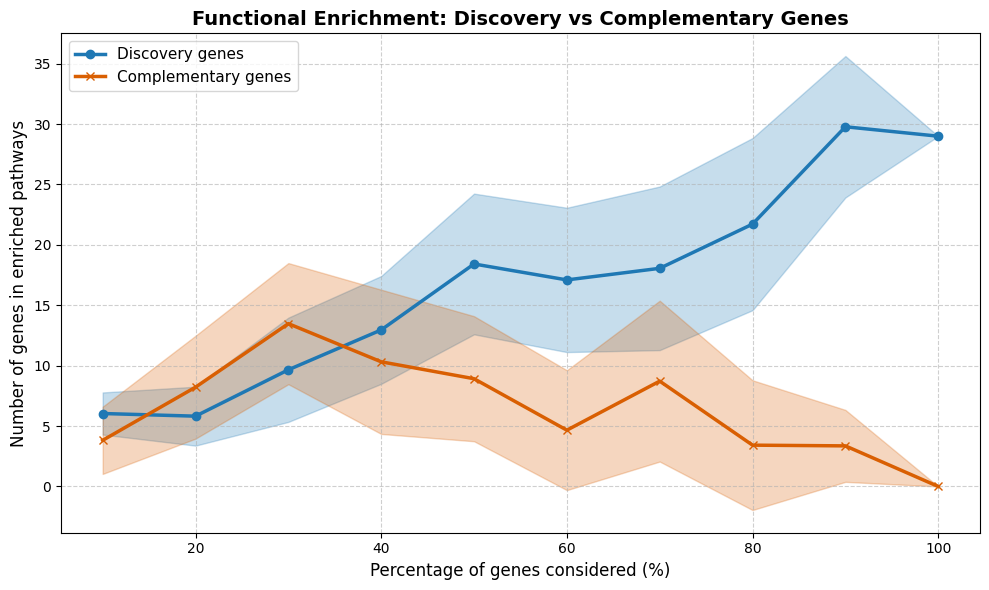

In [ ]:
background_genes = list(set(discovery_genes + complementary_genes))

cumulative_metric_overlap_plot(discovery_genes, complementary_genes, pathway_db, background_genes, steps=10)

**135 vs 135**

In [ ]:
random.seed(20)
matched_control = random.sample(complementary_genes, len(discovery_genes))

In [ ]:
background_genes = list(set(discovery_genes + complementary_genes)) #da capire se tenere 359 o 270(135+135)

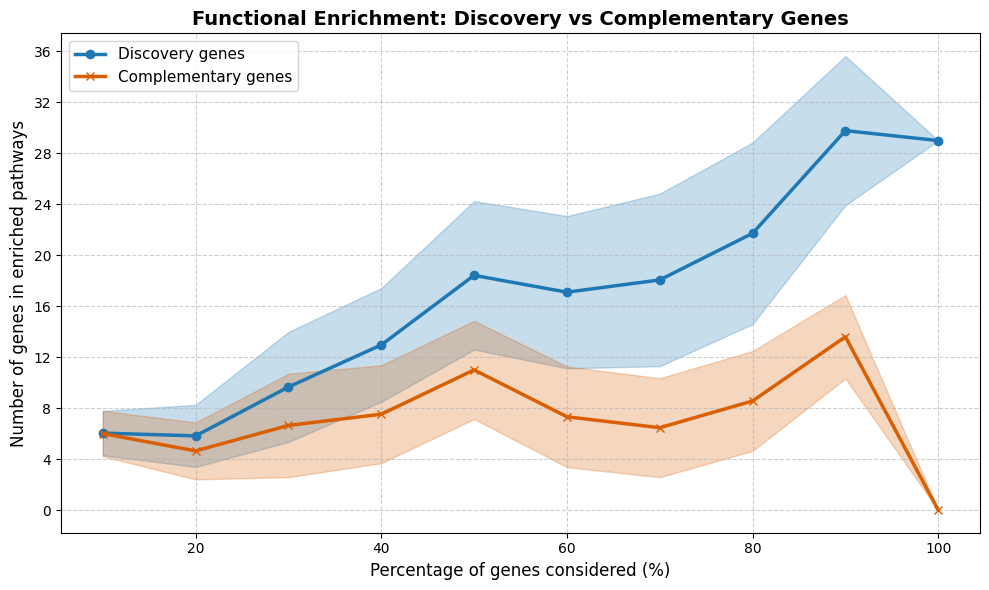

In [ ]:
cumulative_metric_overlap_plot(discovery_genes, matched_control, pathway_db, background_genes, steps=10)
